1. Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels import formula
import warnings
warnings.filterwarnings('ignore')

df_stocks = pd.read_excel("TRD_Mnth.xlsx", skiprows=[1,2])

df_stocks = df_stocks.rename(columns={
        'Stkcd': 'stock_code',
        'Trdmnt': 'date',
        'Msmvosd': 'mkt_cap',
        'Mretnd': 'return',
        'Markettype': 'market_type'
    })

df_stocks['date'] = pd.to_datetime(df_stocks['date'], format='%Y-%m')
df_stocks['year_month'] = df_stocks['date'].dt.to_period('M')
df_stocks['return'] = pd.to_numeric(df_stocks['return'], errors='coerce')
df_stocks['mkt_cap'] = pd.to_numeric(df_stocks['mkt_cap'], errors='coerce')
df_stocks = df_stocks[df_stocks['market_type'] == 4]
df_stocks = df_stocks[(df_stocks['date'] >= '2000-12-01') & (df_stocks['date'] <= '2025-12-31')]
df_stocks = df_stocks.dropna(subset=['return', 'mkt_cap'])

df_stocks.head()

,stock_code,date,mkt_cap,return,market_type,year_month
0,1,2000-12-01,20228171.57,-0.062621,4,2000-12
1,1,2001-01-01,20869008.96,0.031680,4,2001-01
2,1,2001-02-01,19629127.92,-0.059413,4,2001-02
3,1,2001-03-01,22596483.67,0.151171,4,2001-03
4,1,2001-04-01,21635227.58,-0.042540,4,2001-04


In [2]:
df_factors = pd.read_excel("STK_MKT_THRFACMONTH.xlsx", skiprows=[1,2])

df_factors = df_factors.rename(columns={
    'MarkettypeID': 'market_type_id',
    'TradingMonth': 'date',
    'RiskPremium1': 'mkt_risk',
    'SMB1': 'smb',
    'HML1': 'hml'
})

df_factors['date'] = pd.to_datetime(df_factors['date'], format='%Y-%m')
df_factors['year_month'] = df_factors['date'].dt.to_period('M')
df_factors['mkt_risk'] = pd.to_numeric(df_factors['mkt_risk'], errors='coerce')
df_factors['smb'] = pd.to_numeric(df_factors['smb'], errors='coerce')
df_factors['hml'] = pd.to_numeric(df_factors['hml'], errors='coerce')
df_factors = df_factors[df_factors['market_type_id'] == 'P9706']
df_factors = df_factors[(df_factors['date'] >= '2000-12-01') & (df_factors['date'] <= '2025-12-31')]
df_factors = df_factors.dropna(subset=['mkt_risk', 'smb', 'hml'])
df_factors.head()


,market_type_id,date,mkt_risk,smb,hml,year_month
0,P9706,2000-12-01,-0.004273,0.018446,0.009637,2000-12
12,P9706,2001-01-01,-0.010002,-0.010636,0.028226,2001-01
24,P9706,2001-02-01,-0.059877,-0.011976,0.023822,2001-02
36,P9706,2001-03-01,0.073146,0.028609,0.004837,2001-03
48,P9706,2001-04-01,-0.006993,0.031669,-0.024298,2001-04


2(a)(i) Average Monthly Return and t-value

In [3]:
df_stocks = df_stocks.sort_values(['stock_code', 'date'])
df_stocks['lag_mkt_cap'] = df_stocks.groupby('stock_code')['mkt_cap'].shift(1)
df_stocks['lag_return'] = df_stocks.groupby('stock_code')['return'].shift(1)
df_stocks = df_stocks.dropna(subset=['lag_mkt_cap', 'lag_return'])

In [4]:
def construct_size_portfolios(df):

    portfolios = []
    months_with_issues = []

    for (year_month), group in df.groupby('year_month'):
        if len(group) < 20:
            months_with_issues.append(year_month)
            continue

        try:
            group = group.copy()
            group['size_portfolio'] = pd.qcut(group['lag_mkt_cap'],
                                               q=10,
                                               labels=range(1, 11),
                                               duplicates='drop')

            port_returns = group.groupby('size_portfolio')['return'].mean()

            for port_num, ret in port_returns.items():
                portfolios.append({
                    'year_month': year_month,
                    'portfolio': int(port_num),
                    'return': ret
                })
        except Exception as e:
            months_with_issues.append(year_month)
            continue

    if months_with_issues:
        print(f"Warning: Skipped {len(months_with_issues)} months due to insufficient data")

    df_portfolios = pd.DataFrame(portfolios)
    df_wide = df_portfolios.pivot(index='year_month',
                                   columns='portfolio',
                                   values='return')
    df_wide.columns = [f'port_{col}' for col in df_wide.columns]

    for i in range(1, 11):
        if f'port_{i}' not in df_wide.columns:
            df_wide[f'port_{i}'] = np.nan

    df_wide = df_wide[[f'port_{i}' for i in range(1, 11)]]

    df_wide['port_longshort'] = df_wide['port_10'] - df_wide['port_1']

    print(f"\nConstructed {len(df_wide)} monthly size portfolios")
    print(f"Date range: {df_wide.index.min()} to {df_wide.index.max()}")

    return df_wide

print("CONSTRUCTING SIZE PORTFOLIOS (10 DECILES)")

df_size_portfolios = construct_size_portfolios(df_stocks)
print("\nFirst 5 months of size portfolios:")
print(df_size_portfolios.head())
df_size_portfolios.to_excel('2a.xlsx', sheet_name='Size_Portfolios')

CONSTRUCTING SIZE PORTFOLIOS (10 DECILES)

Constructed 300 monthly size portfolios
Date range: 2001-01 to 2025-12

First 5 months of size portfolios:
              port_1    port_2    port_3    port_4    port_5    port_6  \
year_month                                                               
2001-01    -0.034913 -0.017053 -0.014577 -0.000180 -0.001680  0.002140   
2001-02    -0.112851 -0.080681 -0.072425 -0.073217 -0.073424 -0.075761   
2001-03     0.121804  0.107398  0.097743  0.086172  0.094674  0.081690   
2001-04     0.030128  0.010240  0.011176 -0.002570 -0.007284 -0.004358   
2001-05     0.082890  0.088773  0.088276  0.084352  0.059605  0.040563   

              port_7    port_8    port_9   port_10  port_longshort  
year_month                                                          
2001-01    -0.013100 -0.021670 -0.014137 -0.014805        0.020108  
2001-02    -0.067569 -0.061928 -0.054970 -0.048581        0.064270  
2001-03     0.070882  0.074723  0.065609  0.057731     

In [5]:
def analyze_portfolio_returns(df_portfolios, portfolio_cols, name=""):

    results = []

    for col in portfolio_cols:
        returns = df_portfolios[col].dropna()

        if len(returns) == 0:
            continue

        mean_return = returns.mean()
        std_return = returns.std()
        n_obs = len(returns)
        std_error = std_return / np.sqrt(n_obs)
        t_stat = mean_return / std_error
        p_value = stats.ttest_1samp(returns, 0)[1]

        ci_lower = mean_return - 1.96 * std_error
        ci_upper = mean_return + 1.96 * std_error

        results.append({
            'Portfolio': col,
            'Mean_Return': mean_return,
            'Mean_Return_pct': mean_return * 100,
            'Std_Dev': std_return,
            'Std_Error': std_error,
            'T_Statistic': t_stat,
            'P_Value': p_value,
            'CI_Lower': ci_lower,
            'CI_Upper': ci_upper,
            'N_Obs': n_obs,
            'Significant_5pct': p_value < 0.05,
            'Significant_1pct': p_value < 0.01
        })

    return pd.DataFrame(results)

size_cols = [f'port_{i}' for i in range(1, 11)] + ['port_longshort']
size_results = analyze_portfolio_returns(df_size_portfolios, size_cols)

print("PART 2(a)(i): SIZE EFFECT - AVERAGE MONTHLY RETURNS")
print("\nPortfolio | Mean Return (%) | T-Statistic | Significant (5%)")
print("-" * 65)
for _, row in size_results.iterrows():
    port_label = row['Portfolio'].replace('port_', 'Port ').replace('port_longshort', 'Long-Short')
    print(f"{port_label:12} | {row['Mean_Return_pct']:10.4f}% | {row['T_Statistic']:10.4f} | {row['Significant_5pct']}")

PART 2(a)(i): SIZE EFFECT - AVERAGE MONTHLY RETURNS

Portfolio | Mean Return (%) | T-Statistic | Significant (5%)
-----------------------------------------------------------------
Port 1       |     2.5972% |     4.0500 | True
Port 2       |     1.8690% |     3.2261 | True
Port 3       |     1.6450% |     2.9158 | True
Port 4       |     1.3741% |     2.4404 | True
Port 5       |     1.0401% |     1.9169 | False
Port 6       |     0.8472% |     1.5660 | False
Port 7       |     0.9126% |     1.6967 | False
Port 8       |     0.8251% |     1.5942 | False
Port 9       |     0.7882% |     1.5746 | False
Port 10      |     0.7467% |     1.5907 | False
Port longshort |    -1.8505% |    -4.0265 | True


2(a)(ii) Plot Portfolio Number vs. Average Monthly Return

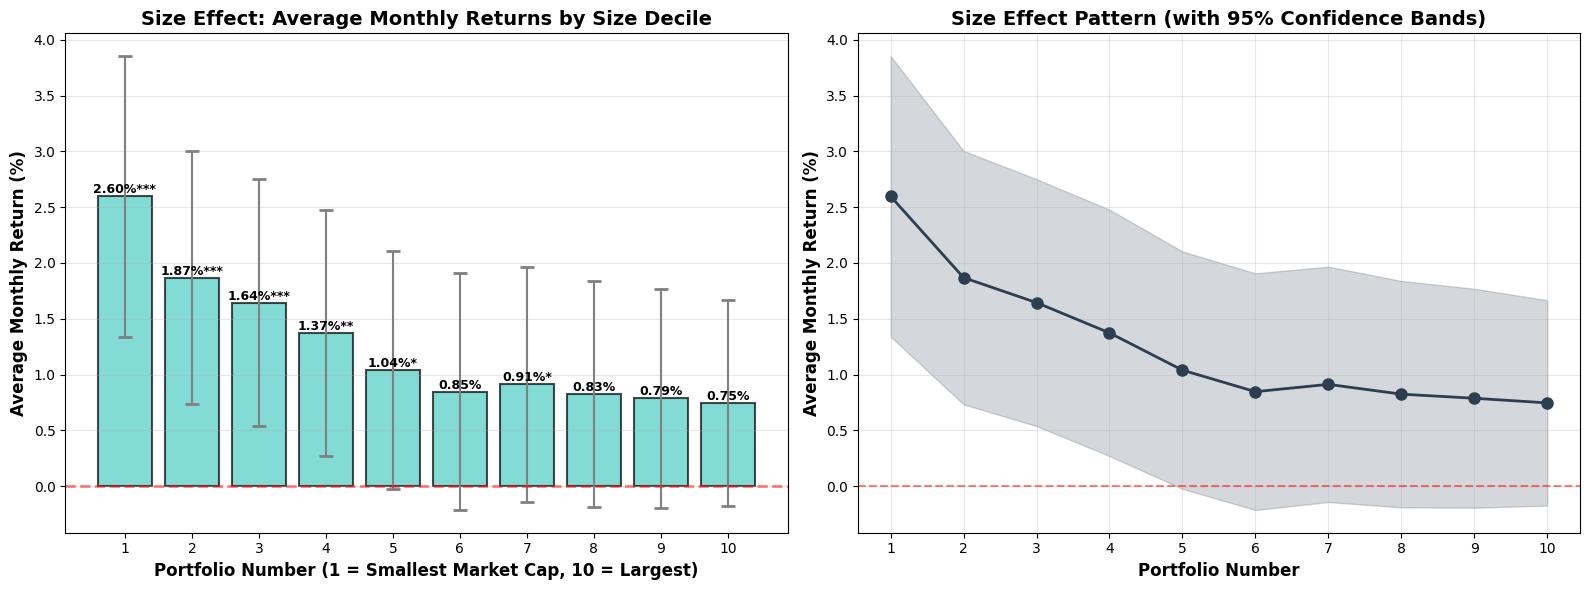

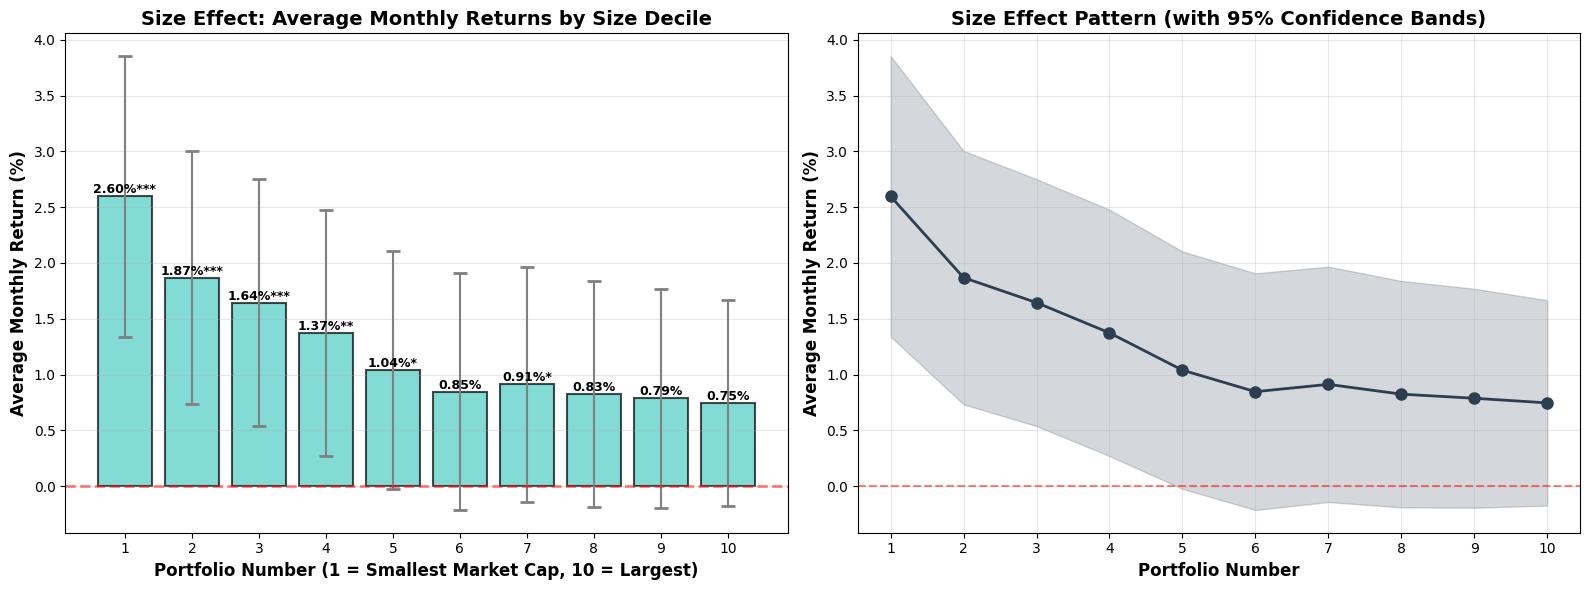

In [9]:
def plot_size_effect(results_df):

    plot_data = results_df[~results_df['Portfolio'].str.contains('longshort')].copy()
    plot_data['Portfolio_Num'] = plot_data['Portfolio'].str.extract('(\d+)').astype(int)
    plot_data = plot_data.sort_values('Portfolio_Num')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    colors = ['#FF6B6B' if x < 0 else '#4ECDC4' for x in plot_data['Mean_Return']]
    bars = ax1.bar(plot_data['Portfolio_Num'],
                   plot_data['Mean_Return_pct'],
                   color=colors,
                   alpha=0.7,
                   edgecolor='black',
                   linewidth=1.5)

    ax1.errorbar(plot_data['Portfolio_Num'],
                plot_data['Mean_Return_pct'],
                yerr=1.96 * plot_data['Std_Error'] * 100,
                fmt='none',
                color='black',
                capsize=5,
                capthick=2,
                ecolor='gray')

    ax1.axhline(y=0, color='red', linestyle='--', alpha=0.5, linewidth=2)

    for bar, value, tstat in zip(bars, plot_data['Mean_Return_pct'], plot_data['T_Statistic']):
        height = bar.get_height()
        stars = '***' if abs(tstat) > 2.58 else ('**' if abs(tstat) > 1.96 else ('*' if abs(tstat) > 1.645 else ''))
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{value:.2f}%{stars}',
                ha='center',
                va='bottom' if height > 0 else 'top',
                fontsize=9,
                fontweight='bold')

    ax1.set_xlabel('Portfolio Number (1 = Smallest Market Cap, 10 = Largest)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Average Monthly Return (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Size Effect: Average Monthly Returns by Size Decile', fontsize=14, fontweight='bold')
    ax1.set_xticks(range(1, 11))
    ax1.grid(True, alpha=0.3, axis='y')

    ax2.plot(plot_data['Portfolio_Num'], plot_data['Mean_Return_pct'],
             marker='o', linewidth=2, markersize=8, color='#2C3E50')
    ax2.fill_between(plot_data['Portfolio_Num'],
                     plot_data['Mean_Return_pct'] - 1.96 * plot_data['Std_Error'] * 100,
                     plot_data['Mean_Return_pct'] + 1.96 * plot_data['Std_Error'] * 100,
                     alpha=0.2, color='#2C3E50')
    ax2.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    ax2.set_xlabel('Portfolio Number', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Average Monthly Return (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Size Effect Pattern (with 95% Confidence Bands)', fontsize=14, fontweight='bold')
    ax2.set_xticks(range(1, 11))
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    #plt.show()

    return fig

plot_size_effect(size_results)

2(a)(iii) CAPM Regression Results

In [10]:
def run_capm_regression(portfolio_returns, factors_df, portfolio_name):

    merged = pd.merge(portfolio_returns.reset_index(), factors_df,
                      on='year_month', how='inner')
    merged = merged.set_index('year_month')

    y = merged[portfolio_name].dropna()
    X = merged['mkt_risk'].loc[y.index]
    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    return model

print("PART 2(a)(iii): SIZE EFFECT - CAPM REGRESSION RESULTS")

capm_results_size = {}

for col in size_cols:
    model = run_capm_regression(df_size_portfolios, df_factors, col)
    capm_results_size[col] = model

    port_name = col.replace('port_', 'Portfolio ').replace('port_longshort', 'Long-Short')
    print(f"\n{port_name}:")
    print(f"  Alpha (α): {model.params['const']*100:8.4f}% per month (t = {model.tvalues['const']:8.4f})")
    print(f"  Market Beta (β₁): {model.params['mkt_risk']:8.4f} (t = {model.tvalues['mkt_risk']:8.4f})")
    print(f"  R-squared: {model.rsquared:8.4f}")
    print(f"  Adj. R-squared: {model.rsquared_adj:8.4f}")
    print(f"  Observations: {int(model.nobs)}")

PART 2(a)(iii): SIZE EFFECT - CAPM REGRESSION RESULTS

Portfolio 1:
  Alpha (α):   2.0231% per month (t =   4.3727)
  Market Beta (β₁):   1.0829 (t =  16.7227)
  R-squared:   0.4841
  Adj. R-squared:   0.4824
  Observations: 300

Portfolio 2:
  Alpha (α):   1.2983% per month (t =   3.4677)
  Market Beta (β₁):   1.0763 (t =  20.5392)
  R-squared:   0.5860
  Adj. R-squared:   0.5846
  Observations: 300

Portfolio 3:
  Alpha (α):   1.0786% per month (t =   3.0429)
  Market Beta (β₁):   1.0682 (t =  21.5306)
  R-squared:   0.6087
  Adj. R-squared:   0.6074
  Observations: 300

Portfolio 4:
  Alpha (α):   0.7851% per month (t =   2.3836)
  Market Beta (β₁):   1.1108 (t =  24.0932)
  R-squared:   0.6608
  Adj. R-squared:   0.6596
  Observations: 300

Portfolio 5:
  Alpha (α):   0.4688% per month (t =   1.4964)
  Market Beta (β₁):   1.0776 (t =  24.5784)
  R-squared:   0.6697
  Adj. R-squared:   0.6686
  Observations: 300

Portfolio 6:
  Alpha (α):   0.2653% per month (t =   0.8896)
  Market 

2(b)i. Equal-Weighted Month Returns for Each Portfolio

In [12]:
def construct_momentum_portfolios(df, n_portfolios=5):

    portfolios = []
    months_with_issues = []

    for (year_month), group in df.groupby('year_month'):
        if len(group) < n_portfolios * 5:
            months_with_issues.append(year_month)
            continue

        try:
            group = group.copy()
            group['mom_portfolio'] = pd.qcut(group['lag_return'],
                                              q=n_portfolios,
                                              labels=range(1, n_portfolios+1),
                                              duplicates='drop')

            port_returns = group.groupby('mom_portfolio')['return'].mean()

            for port_num, ret in port_returns.items():
                portfolios.append({
                    'year_month': year_month,
                    'portfolio': int(port_num),
                    'return': ret
                })
        except Exception as e:
            months_with_issues.append(year_month)
            continue

    df_mom = pd.DataFrame(portfolios)
    df_wide = df_mom.pivot(index='year_month', columns='portfolio', values='return')
    df_wide.columns = [f'mom_port_{col}' for col in df_wide.columns]

    for i in range(1, n_portfolios+1):
        if f'mom_port_{i}' not in df_wide.columns:
            df_wide[f'mom_port_{i}'] = np.nan

    df_wide['mom_longshort'] = df_wide['mom_port_5'] - df_wide['mom_port_1']

    print(f"\nConstructed {len(df_wide)} monthly momentum portfolios")
    return df_wide

print("CONSTRUCTING MOMENTUM PORTFOLIOS (5 GROUPS)")

df_momentum = construct_momentum_portfolios(df_stocks, n_portfolios=5)
print("\nFirst 5 months of momentum portfolios:")
print(df_momentum.head())

df_momentum.to_excel('2b.xlsx', sheet_name='Momentum_Portfolios')

CONSTRUCTING MOMENTUM PORTFOLIOS (5 GROUPS)

Constructed 300 monthly momentum portfolios

First 5 months of momentum portfolios:
            mom_port_1  mom_port_2  mom_port_3  mom_port_4  mom_port_5  \
year_month                                                               
2001-01      -0.012206   -0.002504   -0.001718   -0.019439   -0.029160   
2001-02      -0.081772   -0.077934   -0.079668   -0.062848   -0.058792   
2001-03       0.116846    0.083804    0.088441    0.076829    0.063288   
2001-04       0.007098   -0.017776   -0.008796    0.004352   -0.004568   
2001-05       0.027987    0.041631    0.060879    0.055364    0.061070   

            mom_longshort  
year_month                 
2001-01         -0.016954  
2001-02          0.022979  
2001-03         -0.053558  
2001-04         -0.011666  
2001-05          0.033083  


2(b)ii. Time-series Average Monthly Return and t-value

PART 2(b)(i): MOMENTUM EFFECT - AVERAGE MONTHLY RETURNS

Portfolio | Mean Return (%) | T-Statistic | Significant (5%)
-----------------------------------------------------------------
Port 1                         |     1.7552% |     3.0367 | True
Port 2                         |     1.5950% |     2.9808 | True
Port 3                         |     1.4441% |     2.7342 | True
Port 4                         |     1.1739% |     2.2557 | True
Port 5                         |     0.3553% |     0.6803 | False
Long-Short (Winners-Losers)    |    -1.3999% |    -5.1425 | True


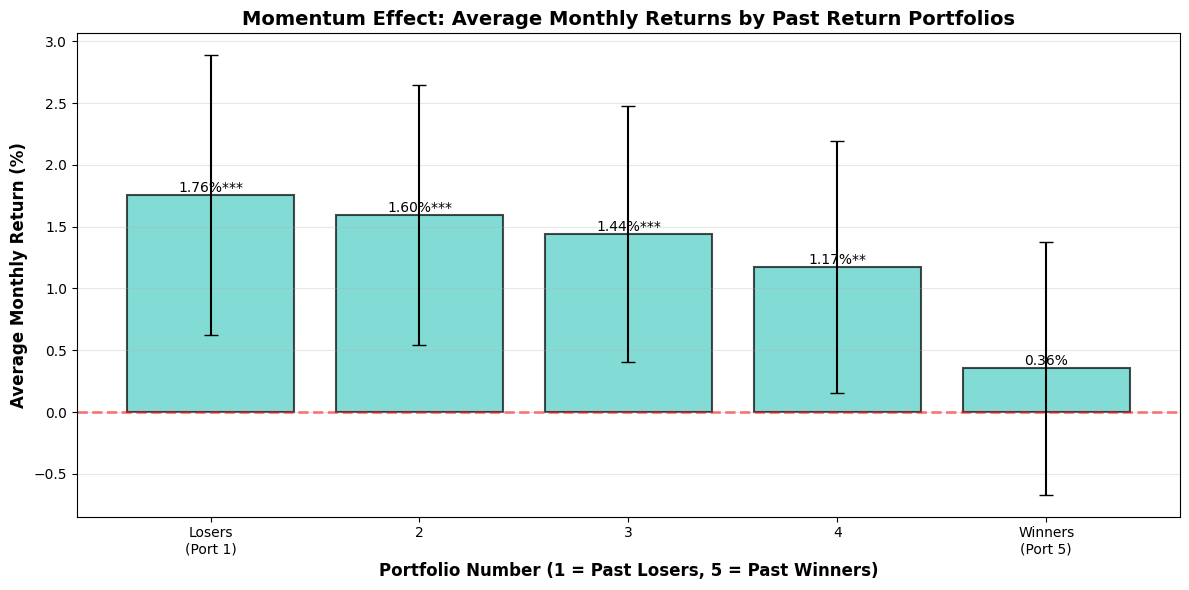

In [13]:
mom_cols = [f'mom_port_{i}' for i in range(1, 6)] + ['mom_longshort']
mom_results = analyze_portfolio_returns(df_momentum, mom_cols)

print("PART 2(b)(i): MOMENTUM EFFECT - AVERAGE MONTHLY RETURNS")
print("\nPortfolio | Mean Return (%) | T-Statistic | Significant (5%)")
print("-" * 65)
for _, row in mom_results.iterrows():
    port_label = row['Portfolio'].replace('mom_port_', 'Port ').replace('mom_longshort', 'Long-Short (Winners-Losers)')
    print(f"{port_label:30} | {row['Mean_Return_pct']:10.4f}% | {row['T_Statistic']:10.4f} | {row['Significant_5pct']}")

fig, ax = plt.subplots(figsize=(12, 6))

plot_data = mom_results[~mom_results['Portfolio'].str.contains('longshort')].copy()
plot_data['Portfolio_Num'] = plot_data['Portfolio'].str.extract('(\d+)').astype(int)
plot_data = plot_data.sort_values('Portfolio_Num')

colors = ['#FF6B6B' if x < 0 else '#4ECDC4' for x in plot_data['Mean_Return']]
bars = ax.bar(plot_data['Portfolio_Num'],
              plot_data['Mean_Return_pct'],
              color=colors,
              alpha=0.7,
              edgecolor='black',
              linewidth=1.5)

ax.errorbar(plot_data['Portfolio_Num'],
            plot_data['Mean_Return_pct'],
            yerr=1.96 * plot_data['Std_Error'] * 100,
            fmt='none', color='black', capsize=5)

ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, linewidth=2)

for bar, value, tstat in zip(bars, plot_data['Mean_Return_pct'], plot_data['T_Statistic']):
    height = bar.get_height()
    stars = '***' if abs(tstat) > 2.58 else ('**' if abs(tstat) > 1.96 else ('*' if abs(tstat) > 1.645 else ''))
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{value:.2f}%{stars}',
            ha='center', va='bottom' if height > 0 else 'top', fontsize=10)

ax.set_xlabel('Portfolio Number (1 = Past Losers, 5 = Past Winners)', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Monthly Return (%)', fontsize=12, fontweight='bold')
ax.set_title('Momentum Effect: Average Monthly Returns by Past Return Portfolios', fontsize=14, fontweight='bold')
ax.set_xticks(range(1, 6))
ax.set_xticklabels(['Losers\n(Port 1)', '2', '3', '4', 'Winners\n(Port 5)'])
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

2(b)iii. Fama-French 3-factor Regression Results


In [14]:
def run_ff3_regression(portfolio_returns, factors_df, portfolio_name):

    merged = pd.merge(portfolio_returns.reset_index(), factors_df,
                      on='year_month', how='inner')
    merged = merged.set_index('year_month')

    y = merged[portfolio_name].dropna()
    X = merged[['mkt_risk', 'smb', 'hml']].loc[y.index]
    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()
    return model

print("PART 2(b)(iii): MOMENTUM - FAMA-FRENCH 3-FACTOR REGRESSIONS")

ff3_results_mom = {}

for col in mom_cols:
    model = run_ff3_regression(df_momentum, df_factors, col)
    ff3_results_mom[col] = model

    port_name = col.replace('mom_port_', 'Portfolio ').replace('mom_longshort', 'Long-Short (Winners-Losers)')
    print(f"\n{port_name}:")
    print(f"  Alpha (α): {model.params['const']*100:8.4f}% per month (t = {model.tvalues['const']:8.4f})")
    print(f"  Market Risk (β₁): {model.params['mkt_risk']:8.4f} (t = {model.tvalues['mkt_risk']:8.4f})")
    print(f"  Size Factor - SMB (β₂): {model.params['smb']:8.4f} (t = {model.tvalues['smb']:8.4f})")
    print(f"  Value Factor - HML (β₃): {model.params['hml']:8.4f} (t = {model.tvalues['hml']:8.4f})")
    print(f"  R-squared: {model.rsquared:8.4f}")
    print(f"  Adj. R-squared: {model.rsquared_adj:8.4f}")
    print(f"  Observations: {int(model.nobs)}")

PART 2(b)(iii): MOMENTUM - FAMA-FRENCH 3-FACTOR REGRESSIONS

Portfolio 1:
  Alpha (α):   0.7568% per month (t =   4.3876)
  Market Risk (β₁):   1.0427 (t =  43.3669)
  Size Factor - SMB (β₂):   0.9100 (t =  23.5225)
  Value Factor - HML (β₃):  -0.3170 (t =  -5.3268)
  R-squared:   0.9148
  Adj. R-squared:   0.9139
  Observations: 300

Portfolio 2:
  Alpha (α):   0.5825% per month (t =   4.9476)
  Market Risk (β₁):   1.0023 (t =  61.0699)
  Size Factor - SMB (β₂):   0.9045 (t =  34.2508)
  Value Factor - HML (β₃):  -0.1223 (t =  -3.0106)
  R-squared:   0.9537
  Adj. R-squared:   0.9532
  Observations: 300

Portfolio 3:
  Alpha (α):   0.4300% per month (t =   3.7709)
  Market Risk (β₁):   1.0062 (t =  63.3125)
  Size Factor - SMB (β₂):   0.8836 (t =  34.5519)
  Value Factor - HML (β₃):  -0.0654 (t =  -1.6630)
  R-squared:   0.9554
  Adj. R-squared:   0.9550
  Observations: 300

Portfolio 4:
  Alpha (α):   0.2112% per month (t =   1.7775)
  Market Risk (β₁):   0.9960 (t =  60.1407)
  Size